In [1]:
#IMPORT LIBS
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from datetime import timedelta
import cartopy.util as cutil
import pandas as pd
#import statsmodels.api as sm
from tqdm import tqdm

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

/home/links/mf671/miniconda3/envs/falwa_env/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


### Uploading CMIP6 dictionaries 

In [2]:
'''
Importing CMIP6 dictionaries
'''
CMIP6_dics = []
# Path to the dataset directory
dictionaries_path = "/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/CMIP6_hist/"

# List all files
dic_file_list = [
    f for f in os.listdir(dictionaries_path)
    if os.path.isfile(os.path.join(dictionaries_path, f)) and 'DAV' in f
]

dic_file_list = sorted(dic_file_list) #just for security

for i in tqdm(range(len(dic_file_list))[:]):
    #print(dictionaries_path + dic_file_list[i])
    CMIP6_dics.append(np.load(dictionaries_path + dic_file_list[i],allow_pickle=True))

100%|█████████████████████████████████████████████████████████████████████| 108/108 [00:06<00:00, 15.78it/s]


### Uploading ERA5 dictionary

In [3]:
dictionary_path = "/emmy-noether/home/mf671/github/greenland_blocking/numpy_dictionaries/ERA5/"
ERA5_dic = np.load(dictionary_path + 'ERA5_dic_GR_block_DAV_jja.npy',allow_pickle=True)

### Plotting BOXPLOTS

In [4]:
def get_distribution_from_dics_list(dics,key_name,block_type='all'):
    population = []
    for model_dic in dics:
        for element in model_dic:
            if block_type == 'upstream':
                if sum(element['WBI'])/len(element['WBI']) > 0:
                    continue
            if block_type == 'retrograding':
                if sum(element['WBI'])/len(element['WBI']) <= 0:
                    continue
            try:
                population.append(sum(element[key_name])/len(element[key_name]))
            except:
                #print(element[key_name])
                population.append(element[key_name])    
    return population
def get_distribution_from_dic(dic,key_name,block_type='all'):
    population = []
    for element in dic:
        if block_type == 'upstream':
            if sum(element['WBI'])/len(element['WBI']) > 0:
                continue
        if block_type == 'retrograding':
            if sum(element['WBI'])/len(element['WBI']) <= 0:
                continue
        try:
            population.append(sum(element[key_name])/len(element[key_name]))
        except:
            #print('no list!')
            population.append(element[key_name])
    return population

Text(0.5, 0, 'intensity')

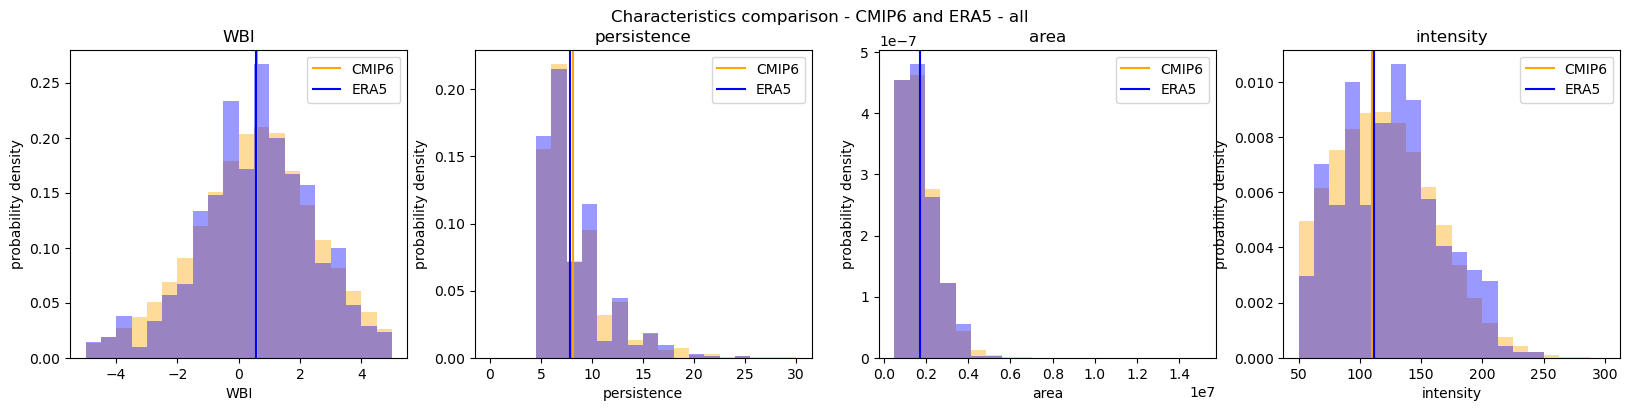

In [5]:
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))
plt.suptitle('Characteristics comparison - CMIP6 and ERA5 - all')


WBIS_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'WBI')
WBIS_ERA5 = get_distribution_from_dic(ERA5_dic,'WBI')

persistences_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'persistence')
persistences_ERA5 = get_distribution_from_dic(ERA5_dic,'persistence')

areas_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'area')
areas_ERA5 = get_distribution_from_dic(ERA5_dic,'area')

intensitys_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'intensity')
intensitys_ERA5 = get_distribution_from_dic(ERA5_dic,'intensity')

axes[0].set_title('WBI')
axes[0].hist(WBIS_CMIP6,bins=20,range=[-5,5],density = True,alpha=0.4,color='orange')
axes[0].hist(WBIS_ERA5,bins=20,range=[-5,5],density = True,alpha=0.4,color='blue')
axes[0].axvline(x=np.mean(np.array(WBIS_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].axvline(x=np.mean(np.array(WBIS_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].legend()
axes[0].set_ylabel('probability density')
axes[0].set_xlabel('WBI')

axes[1].set_title('persistence')
axes[1].hist(persistences_CMIP6,bins=20,range=[0,30],density = True,alpha=0.4,color='orange')
axes[1].hist(persistences_ERA5,bins=20,range=[0,30],density = True,alpha=0.4,color='blue')
axes[1].axvline(x=np.mean(np.array(persistences_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].axvline(x=np.mean(np.array(persistences_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].legend()
axes[1].set_ylabel('probability density')
axes[1].set_xlabel('persistence')

axes[2].set_title('area')
axes[2].hist(areas_CMIP6,bins=20,range=[5e5,1.5e7],density = True,alpha=0.4,color='orange')
axes[2].hist(areas_ERA5,bins=20,range=[5e5,1.5e7],density = True,alpha=0.4,color='blue')
axes[2].axvline(x=np.mean(np.array(areas_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].axvline(x=np.mean(np.array(areas_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].legend()
axes[2].set_ylabel('probability density')
axes[2].set_xlabel('area')

axes[3].set_title('intensity')
axes[3].hist(intensitys_CMIP6,bins=20,range=[50,300],density = True,alpha=0.4,color='orange')
axes[3].hist(intensitys_ERA5,bins=20,range=[50,300],density = True,alpha=0.4,color='blue')
axes[3].axvline(x=np.mean(np.array(intensitys_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[3].axvline(x=np.mean(np.array(intensitys_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[3].legend()
axes[3].set_ylabel('probability density')
axes[3].set_xlabel('intensity')

Text(0.5, 0, 'intensity')

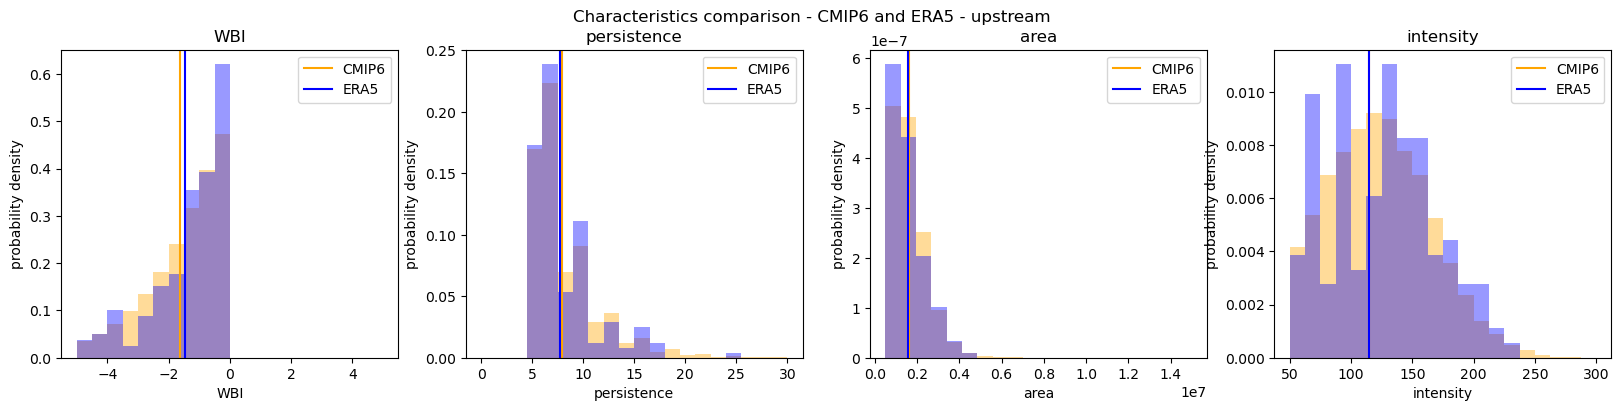

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))
plt.suptitle('Characteristics comparison - CMIP6 and ERA5 - upstream')


WBIS_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'WBI',block_type='upstream')
WBIS_ERA5 = get_distribution_from_dic(ERA5_dic,'WBI',block_type='upstream')

persistences_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'persistence',block_type='upstream')
persistences_ERA5 = get_distribution_from_dic(ERA5_dic,'persistence',block_type='upstream')

areas_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'area',block_type='upstream')
areas_ERA5 = get_distribution_from_dic(ERA5_dic,'area',block_type='upstream')

intensitys_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'intensity',block_type='upstream')
intensitys_ERA5 = get_distribution_from_dic(ERA5_dic,'intensity',block_type='upstream')

axes[0].set_title('WBI')
axes[0].hist(WBIS_CMIP6,bins=20,range=[-5,5],density = True,alpha=0.4,color='orange')
axes[0].hist(WBIS_ERA5,bins=20,range=[-5,5],density = True,alpha=0.4,color='blue')
axes[0].axvline(x=np.mean(np.array(WBIS_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].axvline(x=np.mean(np.array(WBIS_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].legend()
axes[0].set_ylabel('probability density')
axes[0].set_xlabel('WBI')

axes[1].set_title('persistence')
axes[1].hist(persistences_CMIP6,bins=20,range=[0,30],density = True,alpha=0.4,color='orange')
axes[1].hist(persistences_ERA5,bins=20,range=[0,30],density = True,alpha=0.4,color='blue')
axes[1].axvline(x=np.mean(np.array(persistences_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].axvline(x=np.mean(np.array(persistences_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].legend()
axes[1].set_ylabel('probability density')
axes[1].set_xlabel('persistence')

axes[2].set_title('area')
axes[2].hist(areas_CMIP6,bins=20,range=[5e5,1.5e7],density = True,alpha=0.4,color='orange')
axes[2].hist(areas_ERA5,bins=20,range=[5e5,1.5e7],density = True,alpha=0.4,color='blue')
axes[2].axvline(x=np.mean(np.array(areas_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].axvline(x=np.mean(np.array(areas_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].legend()
axes[2].set_ylabel('probability density')
axes[2].set_xlabel('area')

axes[3].set_title('intensity')
axes[3].hist(intensitys_CMIP6,bins=20,range=[50,300],density = True,alpha=0.4,color='orange')
axes[3].hist(intensitys_ERA5,bins=20,range=[50,300],density = True,alpha=0.4,color='blue')
axes[3].axvline(x=np.mean(np.array(intensitys_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[3].axvline(x=np.mean(np.array(intensitys_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[3].legend()
axes[3].set_ylabel('probability density')
axes[3].set_xlabel('intensity')

Text(0.5, 0, 'intensity')

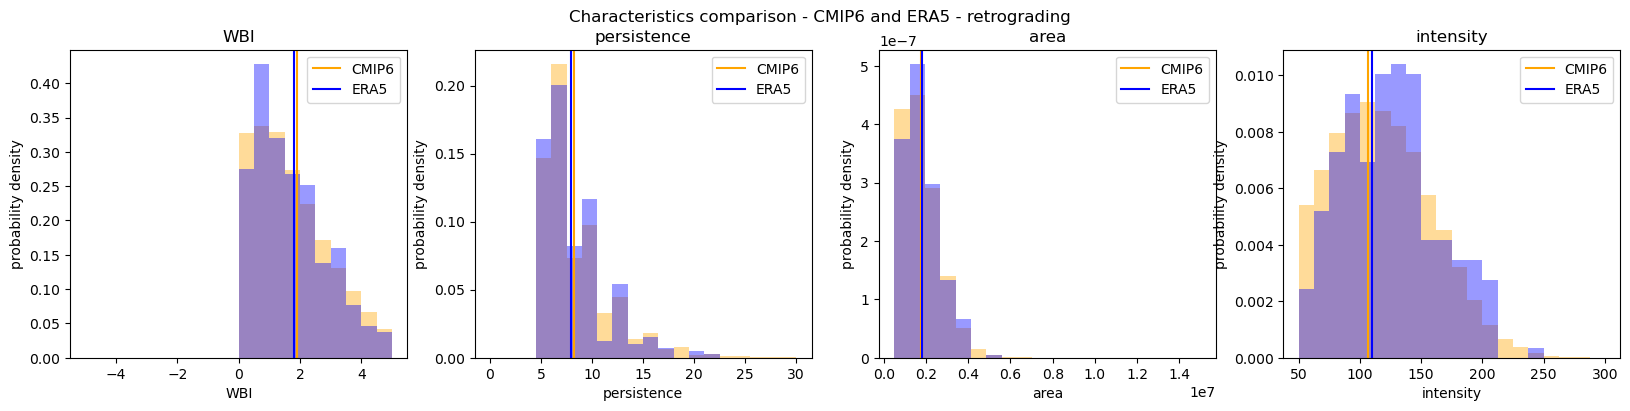

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=4, figsize=(20, 4))
plt.suptitle('Characteristics comparison - CMIP6 and ERA5 - retrograding')


WBIS_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'WBI',block_type='retrograding')
WBIS_ERA5 = get_distribution_from_dic(ERA5_dic,'WBI',block_type='retrograding')

persistences_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'persistence',block_type='retrograding')
persistences_ERA5 = get_distribution_from_dic(ERA5_dic,'persistence',block_type='retrograding')

areas_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'area',block_type='retrograding')
areas_ERA5 = get_distribution_from_dic(ERA5_dic,'area',block_type='retrograding')

intensitys_CMIP6 = get_distribution_from_dics_list(CMIP6_dics,'intensity',block_type='retrograding')
intensitys_ERA5 = get_distribution_from_dic(ERA5_dic,'intensity',block_type='retrograding')

axes[0].set_title('WBI')
axes[0].hist(WBIS_CMIP6,bins=20,range=[-5,5],density = True,alpha=0.4,color='orange')
axes[0].hist(WBIS_ERA5,bins=20,range=[-5,5],density = True,alpha=0.4,color='blue')
axes[0].axvline(x=np.mean(np.array(WBIS_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].axvline(x=np.mean(np.array(WBIS_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[0].legend()
axes[0].set_ylabel('probability density')
axes[0].set_xlabel('WBI')

axes[1].set_title('persistence')
axes[1].hist(persistences_CMIP6,bins=20,range=[0,30],density = True,alpha=0.4,color='orange')
axes[1].hist(persistences_ERA5,bins=20,range=[0,30],density = True,alpha=0.4,color='blue')
axes[1].axvline(x=np.mean(np.array(persistences_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].axvline(x=np.mean(np.array(persistences_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[1].legend()
axes[1].set_ylabel('probability density')
axes[1].set_xlabel('persistence')

axes[2].set_title('area')
axes[2].hist(areas_CMIP6,bins=20,range=[5e5,1.5e7],density = True,alpha=0.4,color='orange')
axes[2].hist(areas_ERA5,bins=20,range=[5e5,1.5e7],density = True,alpha=0.4,color='blue')
axes[2].axvline(x=np.mean(np.array(areas_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].axvline(x=np.mean(np.array(areas_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[2].legend()
axes[2].set_ylabel('probability density')
axes[2].set_xlabel('area')

axes[3].set_title('intensity')
axes[3].hist(intensitys_CMIP6,bins=20,range=[50,300],density = True,alpha=0.4,color='orange')
axes[3].hist(intensitys_ERA5,bins=20,range=[50,300],density = True,alpha=0.4,color='blue')
axes[3].axvline(x=np.mean(np.array(intensitys_CMIP6)), color='orange',label='CMIP6')#, linestyle='STYLE', linewidth=WIDTH)
axes[3].axvline(x=np.mean(np.array(intensitys_ERA5)), color='blue',label='ERA5')#, linestyle='STYLE', linewidth=WIDTH)
axes[3].legend()
axes[3].set_ylabel('probability density')
axes[3].set_xlabel('intensity')